In [1]:
import sys
sys.path.append('../')
from utils import *
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from collections import Counter
from sklearn.cluster import KMeans
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier



In [3]:
#import the data and clean it a little
raw_data = pd.read_csv("solar_panels_dataset_with_states_votes_incentives.csv", index_col=0)

features = ['avg GHI (W/m^2)',
            'ACS: number of households (2016)',
            'ACS: housing unit density (/mile^2, 2016)',
            'ACS: median household income (inflation adjusted $ in 2016, 2016)',
            'ACS: % housing units occupied (2016)',
            'ACS: % housing units occupied by renters (2016)',
            'ACS: avg number of years of education (2016)',
            'ACS: median age',
            'ACS: racial diversity (Gini Simpson index)',
            'frac_dem_votes',
            'incentive_level']

columns = features + ['cumulative num of residential PVs by 2016', 'number of buildings', 'state']

raw_data = raw_data.dropna(axis=0, how='any', subset=columns) #drop all the rows that have any missing values in the columns we care about
raw_data = raw_data[raw_data['number of buildings']>0] #only keep rows with at least some buildings in them

In [6]:
#group by state
#columns += ['code', 'state']
state_raw_data = raw_data[columns].groupby('state').agg({
    'avg GHI (W/m^2)':'mean', 
    'ACS: number of households (2016)':'sum', 
    'ACS: housing unit density (/mile^2, 2016)':'mean',
    'ACS: median household income (inflation adjusted $ in 2016, 2016)':'median', 
    'ACS: % housing units occupied (2016)':'mean', 
    'ACS: % housing units occupied by renters (2016)':'mean',
    'ACS: avg number of years of education (2016)':'mean', 
    'ACS: median age': 'median', 
    'ACS: racial diversity (Gini Simpson index)':'mean',
    'frac_dem_votes':'mean',
    'incentive_level':'mean',
    'cumulative num of residential PVs by 2016':'sum',
    'number of buildings':'sum'
})

state_raw_data=state_raw_data.reset_index()

In [14]:
state_raw_data_features=state_raw_data[features]
scaler = StandardScaler()
state_raw_data_numeric = scaler.fit_transform(state_raw_data_features)

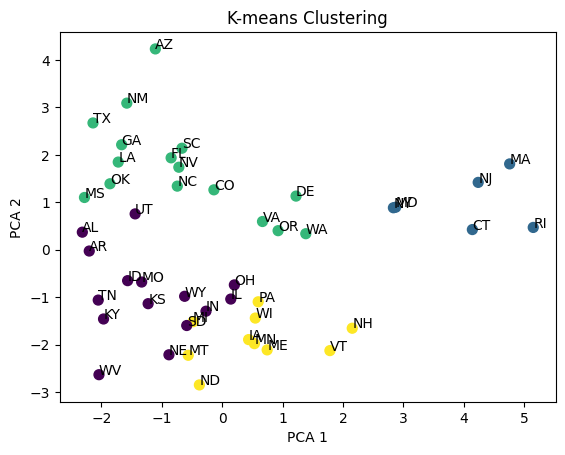

In [18]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(state_raw_data_numeric)

# perform K-means clustering
kmeans = KMeans(n_clusters=4, n_init='auto', random_state=42)
y_kmeans = kmeans.fit_predict(state_raw_data_numeric)

# visualize the results
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, s=50, cmap='viridis')

# add state labels
for i, state in enumerate(state_raw_data['state']):
    plt.annotate(state, (X_pca[i, 0], X_pca[i, 1]))
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('K-means Clustering')
plt.show()
